# Diabetes Prediction Using Support Vector Machine (SVM)

This project demonstrates a binary classification workflow using Support Vector Machine (SVM) on the diabetes dataset provided by Scikit-learn. The continuous target is converted into two classes using the median value.

**Note:** This is an educational classification exercise, not a clinical diabetes diagnosis model.

In [5]:
#Step 1: Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, classification_report

In [6]:
# Step 2: Load the Diabetes Dataset
from sklearn.datasets import load_diabetes
# Load dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Convert target into binary classification (diabetes vs non-diabetes)
df['target'] = (df['target'] > df['target'].median()).astype(int)  # Convert to 0 or 1
# convert it into a binary classification problem by setting values above the median as 1 (diabetes) and below as 0 (non-diabetes).
# Features (X) and Target (y)
X = df.drop(columns=['target'])
y = df['target']

# Print features and target
print(X)
print(y)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  
0   -0.002592  0.019907 -0.017646  
1  

In [7]:
#Step 3: Train-Test Split & Standardization
# Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)# Stratify=y → Ensures equal distribution of classes in train & test sets.

# Standardize features (SVM works better with standardized data)
scaler = StandardScaler() # StandardScaler → Standardizes features (mean = 0, std = 1) to improve SVM performance
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# Step 4: Train an SVM Classifier
# Train SVM with RBF Kernel
svm_model = SVC(kernel='rbf', probability=True, random_state=42) # RBF Kernel → Handles non-linearly separable data. probability=True → Enables AUC-ROC computation
svm_model.fit(X_train_scaled, y_train)

SVC(probability=True, random_state=42)

In [9]:
# Print Model Parameters
#print("Intercept (Bias):", svm_model.intercept_)  # Bias term
#print("Coefficients (Weights):", svm_model.coef_)  # Feature Weights

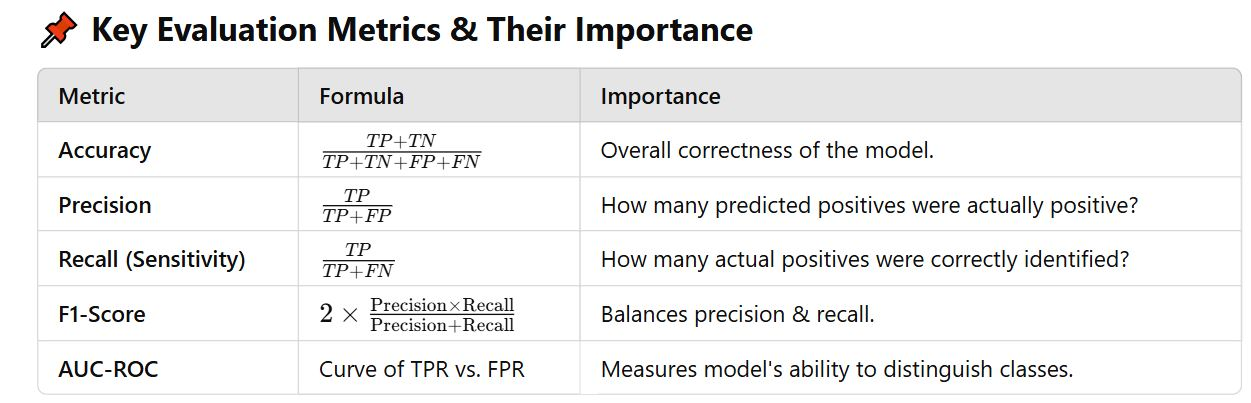

Accuracy (Train): 0.813
Accuracy (Test): 0.742

Precision (Train): 0.814
Precision (Test): 0.714

Recall (Train): 0.814
Recall (Test): 0.795

F1-Score (Train): 0.814
F1-Score (Test): 0.753

AUC-ROC (Train): 0.813
AUC-ROC (Test): 0.742



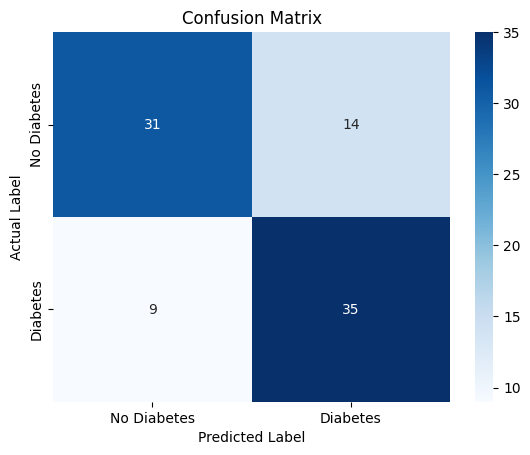

In [10]:
# Step 5: Model Evaluation (Confusion Matrix, Accuracy, Precision, Recall, F1-Score, AUC-ROC)
# Predictions on Training & Test Data
y_train_pred = svm_model.predict(X_train_scaled)
y_test_pred = svm_model.predict(X_test_scaled)


# Performance Metrics Calculation
metrics = {
    "Accuracy": accuracy_score,
    "Precision": precision_score,
    "Recall": recall_score,
    "F1-Score": f1_score,
    "AUC-ROC": roc_auc_score
}

# Print Scores
for metric_name, metric_func in metrics.items():
    print(f"{metric_name} (Train): {metric_func(y_train, y_train_pred):.3f}")
    print(f"{metric_name} (Test): {metric_func(y_test, y_test_pred):.3f}\n")

# Confusion Matrix on test data
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [11]:
# Generate and print classification report
report = classification_report(y_test, y_test_pred)
print(report)

              precision    recall  f1-score   support

           0       0.78      0.69      0.73        45
           1       0.71      0.80      0.75        44

    accuracy                           0.74        89
   macro avg       0.74      0.74      0.74        89
weighted avg       0.74      0.74      0.74        89



Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.69      0.73        45
           1       0.71      0.80      0.75        44

    accuracy                           0.74        89
   macro avg       0.74      0.74      0.74        89
weighted avg       0.74      0.74      0.74        89



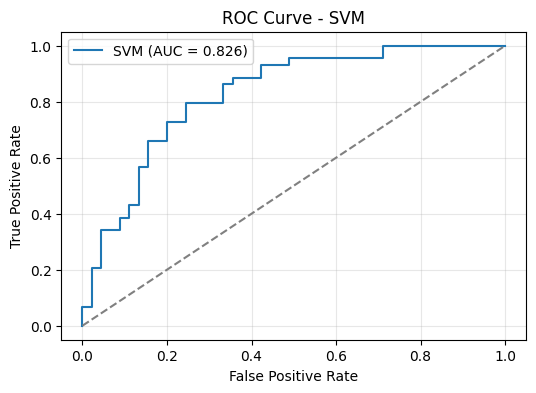

Training Accuracy: 0.8130
Testing Accuracy: 0.7416
The model may be overfitting.


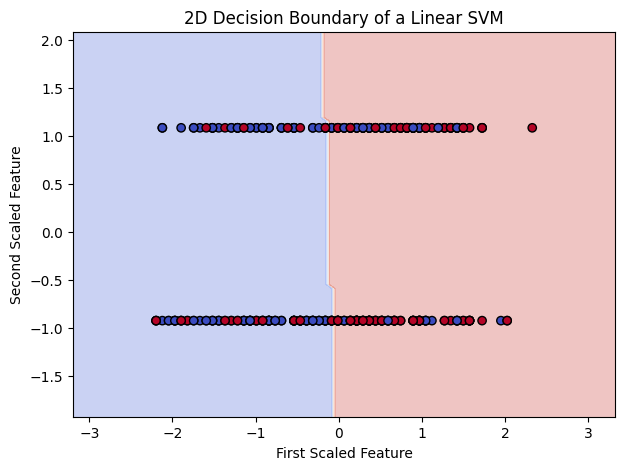

In [12]:

# Step 6: Classification Report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))


# Step 7: Plot ROC Curve
y_test_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_test_prob)
roc_auc = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"SVM (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Step 8: Compare Training and Testing Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")

if train_acc - test_acc > 0.05:
    print("The model may be overfitting.")
elif train_acc < 0.70 and test_acc < 0.70:
    print("The model may be underfitting.")
else:
    print("No obvious overfitting or underfitting based on these accuracy checks.")


# Step 9: Visualize a 2D Linear SVM Decision Boundary
# This is a separate model using only the first two scaled features.
X_vis = X_train_scaled[:, :2]

svm_vis = SVC(kernel="linear")
svm_vis.fit(X_vis, y_train)

x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 100),
    np.linspace(y_min, y_max, 100)
)

Z = svm_vis.predict(
    np.c_[xx.ravel(), yy.ravel()]
).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_vis[:, 0],
    X_vis[:, 1],
    c=y_train,
    edgecolors="k",
    cmap="coolwarm"
)

plt.xlabel("First Scaled Feature")
plt.ylabel("Second Scaled Feature")
plt.title("2D Decision Boundary of a Linear SVM")
plt.show()


##Conclusion

The SVM classifier achieved a test accuracy of **74.16%** and a ROC-AUC score of **0.826**. The results demonstrate the application of feature standardization, SVM classification, and multiple evaluation metrics.

The target classes were artificially derived from the median of a disease-progression measure. Therefore, the results should be interpreted as an educational machine learning exercise, not as a method for diagnosing diabetes.